# LeetCode #77: Combinations

https://leetcode.com/problems/combinations/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O\!\left(\binom{n}{k} \cdot k\right)$ | $O(k)$ |
| **Optimal: Backtracking + Pruning ★** | $O\!\left(\binom{n}{k} \cdot k\right)$ | $O(k)$ |

---

## Understanding the Methods

### Brute Force
Recurse from each starting index without any early exit. Even when fewer than k elements remain in the range [start, n], the recursion still descends, returns without adding anything, and wastes time.

### Optimal: Backtracking + Pruning ★
At each step, only recurse if there are enough elements left to complete the combination: `i <= n - (k - path.size()) + 1`. This upper-bound prune eliminates all branches that cannot possibly fill the remaining slots.

**Why this is better than Brute Force:** The pruning condition cuts branches the moment they become dead ends, avoiding unnecessary function calls. The asymptotic complexity is the same, but the constant factor is meaningfully smaller.

**Constraints:**
* 1 <= n <= 20
* 1 <= k <= n

## Solutions

### C#

In [ ]:
public class Solution {
    public IList<IList<int>> Combine(int n, int k) {
        var result = new List<IList<int>>();
        Backtrack(n, k, 1, new List<int>(), result);
        return result;
    }

    private void Backtrack(int n, int k, int start, List<int> path, IList<IList<int>> result) {
        if (path.Count == k) {
            result.Add(new List<int>(path));
            return;
        }
        // Upper bound: only recurse if enough elements remain to fill the combination
        int remaining = k - path.Count;
        for (int i = start; i <= n - remaining + 1; i++) {
            path.Add(i);
            Backtrack(n, k, i + 1, path, result);
            // Undo the choice to explore siblings
            path.RemoveAt(path.Count - 1);
        }
    }
}

### Python

In [ ]:
class Solution:
    def combine(self, n: int, k: int) -> list[list[int]]:
        result = []

        def backtrack(start: int, path: list[int]) -> None:
            if len(path) == k:
                result.append(list(path))
                return
            # Upper bound: only recurse if enough elements remain to fill the combination
            remaining = k - len(path)
            for i in range(start, n - remaining + 2):
                path.append(i)
                backtrack(i + 1, path)
                # Undo the choice to explore siblings
                path.pop()

        backtrack(1, [])
        return result

### Go

In [ ]:
func combine(n int, k int) [][]int {
    result := [][]int{}
    path := []int{}

    var backtrack func(start int)
    backtrack = func(start int) {
        if len(path) == k {
            combo := make([]int, k)
            copy(combo, path)
            result = append(result, combo)
            return
        }
        // Upper bound: only recurse if enough elements remain to fill the combination
        remaining := k - len(path)
        for i := start; i <= n-remaining+1; i++ {
            path = append(path, i)
            backtrack(i + 1)
            // Undo the choice to explore siblings
            path = path[:len(path)-1]
        }
    }
    backtrack(1)
    return result
}

### Rust

In [ ]:
impl Solution {
    pub fn combine(n: i32, k: i32) -> Vec<Vec<i32>> {
        let mut result = Vec::new();
        let mut path = Vec::new();
        Self::backtrack(n, k, 1, &mut path, &mut result);
        result
    }

    fn backtrack(n: i32, k: i32, start: i32, path: &mut Vec<i32>, result: &mut Vec<Vec<i32>>) {
        if path.len() == k as usize {
            result.push(path.clone());
            return;
        }
        // Upper bound: only recurse if enough elements remain to fill the combination
        let remaining = k - path.len() as i32;
        for i in start..=(n - remaining + 1) {
            path.push(i);
            Self::backtrack(n, k, i + 1, path, result);
            // Undo the choice to explore siblings
            path.pop();
        }
    }
}

## Example Scenarios

### 1. Common Case
**Input:** n = 4, k = 2
Backtracking picks increasing values: from start=1 we reach [1,2],[1,3],[1,4]; from 2 we reach [2,3],[2,4]; from 3 we reach [3,4]. Starting at 4 is pruned (too few elements remain). Total: $\binom{4}{2} = 6$ combinations.

### 2. Slightly Complex
**Input:** n = 10, k = 3
The bound $i \le n-(k-\text{len})+1$ kicks in immediately: at depth 0, $i$ only runs to 8, since starting at 9 or 10 leaves fewer than the 2 remaining elements needed. All $\binom{10}{3} = 120$ combinations are produced with no wasted recursive calls.

### 3. Edge Case: Time Factor
**Input:** n = 20, k = 10 (maximum size, highest branching)
$\binom{20}{10} = 184{,}756$ combinations, each length 10, must be emitted — the maximum-work case. Pruning still keeps the tree from fanning out uselessly at the shallow levels (only starts $1..11$ survive at depth 0).

### 4. Edge Case: Space Factor
**Input:** n = 20, k = 10
Only the current root-to-leaf path lives on the call stack, so recursion depth and the `path` list are both at most $k = 10$. Auxiliary memory during the DFS is $O(k)$; the $184{,}756$ outputs are what dominate total memory.

### 5. Almost-Impossible but Plausible
**Input:** n = 20, k = 1
With $k=1$ every element is its own combination, and the upper bound equals $n$, so nothing is pruned. Recursion depth is 1, yielding 20 single-element combinations — the algorithm handles the vacuous-pruning case correctly.


## Infographic

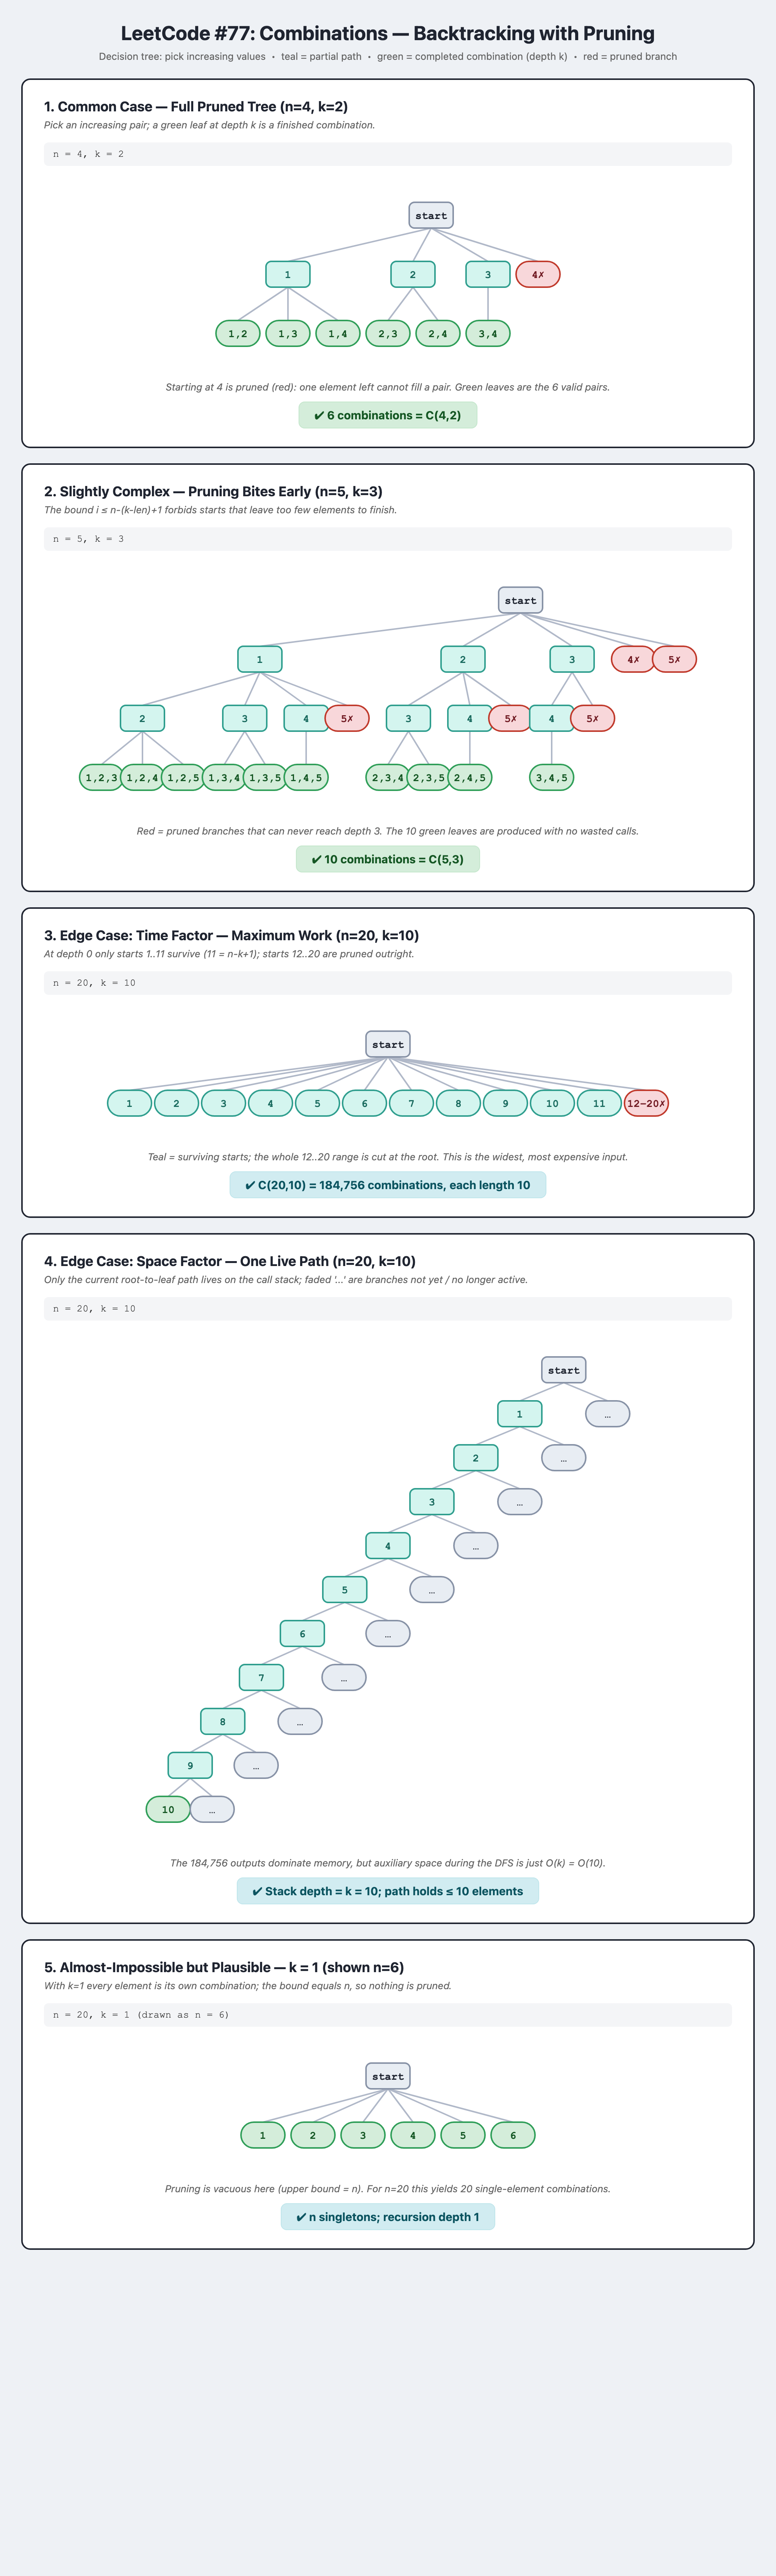